![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# NLP Fundamentals
*Data Science & Machine Learning - Week 7, Day 1*

""
""
## How to use this notebook

In Project 2 every dataset was a table: rows of customers or houses, and columns of numbers and categories. Most of the world's data is not like that. Emails, reviews, support tickets, contracts and posts are **text**, and a model cannot read text, only numbers.

**Natural Language Processing (NLP)** is the set of techniques that turn text into something a model can use. Today you learn the classic way to do it, which is still the first thing to try on any text problem:

1. **Clean** the text: lowercase it and remove what you do not want to count (HTML, links, numbers, punctuation).
2. **Split** it into tokens, usually words, and optionally remove stop words and reduce each word to a base form.
3. **Count** the words: every document becomes a row and every word in the vocabulary a column (**Bag-of-Words**), optionally weighted by how rare each word is (**TF-IDF**).
4. **Model**: the result is an ordinary feature matrix, so everything from Weeks 4 to 6 works on it, including pipelines, cross-validation and grid search.

The running example is a set of about 3,800 forum posts on four topics. By the end you will have a classifier that reads a post it has never seen and says which forum it belongs to.

The slides **1. NLP** in this folder go with the notebook (there is a PDF copy too). Run the cells in order: later sections reuse the data and objects of earlier ones. The **Appendix** has extra material that is not part of the lesson.
""
""

""
""
## Table of contents

- [Setup](#Setup)
- [1. Text is data](#1.-Text-is-data)
- [2. Cleaning text with regular expressions](#2.-Cleaning-text-with-regular-expressions)
- [3. Tokenising](#3.-Tokenising)
- [4. Stop words](#4.-Stop-words)
- [5. Stemming and lemmatisation](#5.-Stemming-and-lemmatisation)
    - [Lemmatisation needs the part of speech](#Lemmatisation-needs-the-part-of-speech)
- [6. Bag-of-Words](#6.-Bag-of-Words)
    - [A sparse matrix](#A-sparse-matrix)
    - [Controlling the vocabulary](#Controlling-the-vocabulary)
- [7. TF-IDF](#7.-TF-IDF)
    - [TF-IDF by hand](#TF-IDF-by-hand)
    - [TF-IDF on a real post](#TF-IDF-on-a-real-post)
- [8. A text classifier](#8.-A-text-classifier)
    - [Fit on train, transform on everything else](#Fit-on-train,-transform-on-everything-else)
    - [Comparing models with cross-validation](#Comparing-models-with-cross-validation)
    - [Tuning and testing once](#Tuning-and-testing-once)
    - [What the model learned](#What-the-model-learned)
- [9. Does more preprocessing help?](#9.-Does-more-preprocessing-help?)
- [10. What Bag-of-Words cannot see](#10.-What-Bag-of-Words-cannot-see)
- [Summary](#Summary)
- [Appendix](#Appendix)
""
""

## Setup

The first run downloads two things: the forum posts (about 14 MB, cached in `~/scikit_learn_data`) and four small NLTK resources (a tokeniser, a stop-word list, the WordNet dictionary and a part-of-speech tagger). Both need an internet connection the first time only.

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.stem.snowball import SnowballStemmer

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

for resource in ["punkt_tab", "stopwords", "wordnet", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

pd.set_option("display.max_colwidth", 120)

""
""
## 1. Text is data

NLP is behind many things you use every day: the spam filter in your inbox, the autocomplete on your phone, the "was this review positive?" score on a shop, the routing of a support ticket to the right team, and the chatbots of this week and next. Most of these are **classification** problems with text as the input, which is exactly what you build today.

The dataset is **20 Newsgroups**, a classic collection of posts from online discussion forums. We keep four forums with very different topics: computer graphics, ice hockey, space, and Middle East politics. Headers, signatures and quoted replies are removed, so the model has to work from what people actually wrote.
""
""

In [2]:
categories = ["comp.graphics", "rec.sport.hockey", "sci.space", "talk.politics.mideast"]
news = fetch_20newsgroups(subset="all", categories=categories, remove=("headers", "footers", "quotes"), random_state=0)

posts = pd.DataFrame({"text": news.data, "topic": [news.target_names[t] for t in news.target]})
print(posts.shape)
posts["topic"].value_counts()

(3899, 2)


topic
rec.sport.hockey         999
sci.space                987
comp.graphics            973
talk.politics.mideast    940
Name: count, dtype: int64

About 3,900 posts, almost perfectly balanced across the four topics. Here is what they look like:

In [3]:
for topic in categories:
    example = posts.loc[posts["topic"] == topic, "text"].iloc[1]
    print(f"--- {topic} ---")
    print(example.strip()[:300], "\n")

--- comp.graphics ---
Pascal Perret, in article <1993Apr21.125750.263@eicn.etna.ch>, wrote

Funny thing, the InterNet: I have no idea what xv221 might be - except that it
might be something to do with X-windows on PCs (? If you know, and have used
it, and think that it is good, email me. [ryanph@mrl.dsto.gov.au]).

DV/X  

--- rec.sport.hockey ---
Standings reflecting 2 completed series in Round 1:

    Participant                Points   Final 4
 1. roland_behunin                  5   CAL-6 QUE-7 QUE-7 
    Dave_Wessels                    5   VAN-7 PIT-6 PIT-5 
 3. Barfly                          0   TOR-6 BOS-7 TOR-6 
    Dean's             

--- sci.space ---
In the April edition of "One Small Step for a Space Activist",
Allen Sherzer & Tim Kyger write:
  "Another problem is what are called 'wraps' (or sometimes
   the 'center tax'). When work for a large program like
   Freedom or Shuttle is performed at a NASA center, the
   center skims off a portion  

--- talk.politics.mideast 

""
""
Real text is messy: line breaks, numbers, capital letters, typos, and posts that are a single line next to posts that are pages long. Before going further, look at the lengths, because some posts are empty once the headers and quotes are gone.
""
""

In [4]:
posts["n_chars"] = posts["text"].str.strip().str.len()
print(posts["n_chars"].describe().round(0))
print("Posts with 20 characters or fewer:", (posts["n_chars"] <= 20).sum())

count     3899.0
mean      1434.0
std       4343.0
min          0.0
25%        241.0
50%        508.0
75%       1107.0
max      74878.0
Name: n_chars, dtype: float64
Posts with 20 characters or fewer: 117


""
""
Half the posts are under about 500 characters, but the longest is over 70,000. 117 posts are empty or almost empty: they were nothing but a quoted reply. They carry no information, so we drop them.

Then, as always, **split before doing anything else**. The test set stays locked away until the very end of section 8.
""
""

In [5]:
posts = posts[posts["n_chars"] > 20].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    posts["text"], posts["topic"], test_size=0.25, stratify=posts["topic"], random_state=0
)
print(f"Training posts: {len(X_train)}   Test posts: {len(X_test)}")

Training posts: 2836   Test posts: 946


""
""
## 2. Cleaning text with regular expressions

A model will treat `Space`, `space` and `space!` as three different words unless we tell it otherwise. Cleaning decides **which differences matter**. The usual tool is **regular expressions** (the `re` module), a mini-language for describing patterns in text.

These are the patterns you need most often:

| Pattern | Matches | Example |
|---|---|---|
| `\d` | one digit | `555`, `2031` |
| `\w` | one letter, digit or underscore | `a`, `7`, `_` |
| `\s` | one space, tab or line break | |
| `[^a-z]` | one character that is **not** a lowercase letter | `!`, `5`, `é` |
| `+` | one or more of the previous | `\s+` = a run of spaces |
| `<[^>]+>` | an HTML tag | `<b>`, `</div>` |

`re.sub(pattern, replacement, text)` replaces every match. A typical cleaning function chains a few of them. The order matters: remove tags and links *before* removing punctuation, otherwise their pieces stay behind as fake words.
""
""

In [6]:
def clean_text(text):
    text = re.sub(r"<[^>]+>", " ", text)            # HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)    # links
    text = re.sub(r"[^a-zA-Z]", " ", text)           # everything that is not a letter
    text = re.sub(r"\s+", " ", text)                 # runs of spaces -> one space
    return text.lower().strip()

message = "WIN $500 now!!! Visit <b>www.free-prizes.com</b> or call 555-1234. Offer ends 31/12."
print(clean_text(message))

win now visit or call offer ends


""
""
The tag, the link, the amount, the phone number and the date are gone, and what remains is lowercase words.

Every cleaning step **throws information away**, so it is a modelling decision, not a chore. Here `$500` and the phone number disappeared, yet "contains an amount of money" is a strong spam signal. The lab adds features like that back on purpose. In the forum data, numbers such as `2031` might help to recognise space posts. There is no universal cleaning recipe: you choose the steps for the problem, and you measure (section 9).
""
""

""
""
## 3. Tokenising

**Tokenising** splits text into units called **tokens**, usually words. Splitting on spaces is the obvious idea, and it is not quite good enough:
""
""

In [7]:
sentence = "Don't panic: NASA's rovers aren't landing on Mars until 2031."
print("split():       ", sentence.split())
print("word_tokenize: ", word_tokenize(sentence))

split():        ["Don't", 'panic:', "NASA's", 'rovers', "aren't", 'landing', 'on', 'Mars', 'until', '2031.']
word_tokenize:  ['Do', "n't", 'panic', ':', 'NASA', "'s", 'rovers', 'are', "n't", 'landing', 'on', 'Mars', 'until', '2031', '.']


""
""
`split()` leaves punctuation stuck to the words (`panic:`, `2031.`), so `panic:` and `panic` would be two different words. NLTK's `word_tokenize` separates punctuation and splits contractions in a consistent way (`Do` + `n't`, `NASA` + `'s`).

You will rarely call a tokeniser yourself for Bag-of-Words, because scikit-learn's vectorisers have a simple one built in (section 6). It is still worth knowing what a token is, because everything later counts tokens. On Day 3 you will meet the tokenisers of transformer models, which split rare words into smaller pieces.
""
""

""
""
## 4. Stop words

Some words appear in almost every text, whatever the topic: *the*, *of*, *to*, *and*. They are called **stop words**. Here are the most frequent words in the training posts:
""
""

In [8]:
counter = CountVectorizer().fit(X_train)
word_counts = pd.Series(np.asarray(counter.transform(X_train).sum(axis=0)).ravel(), index=counter.get_feature_names_out())
word_counts.sort_values(ascending=False).head(10)

the     36652
of      16371
to      16125
and     15307
in      11288
that     7470
is       7450
it       6328
for      6149
on       5086
dtype: int64

""
""
All ten are stop words, and none of them helps to tell hockey from space. Removing them makes the data smaller and the most frequent words more informative. NLTK has a list of about 200 English stop words:
""
""

In [9]:
english_stop_words = stopwords.words("english")
print(len(english_stop_words), english_stop_words[:15])
print("'not' is a stop word:", "not" in english_stop_words, "  'no' is a stop word:", "no" in english_stop_words)

198 ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't"]
'not' is a stop word: True   'no' is a stop word: True


""
""
Look at the last line. **`not` and `no` are on the list**, and that can hurt. For topic classification it does not matter, but for sentiment it can reverse the meaning:
""
""

In [10]:
review = "The service was not bad at all"
print([w for w in word_tokenize(review.lower()) if w not in english_stop_words])

['service', 'bad']


""
""
A positive review became `service bad`. So stop-word removal is another decision to make per problem: for sentiment, keep negations, or skip stop-word removal altogether and let TF-IDF down-weight common words for you (section 7).
""
""

""
""
## 5. Stemming and lemmatisation

*launch*, *launched*, *launches* and *launching* are four different tokens, but for a topic classifier they mean the same thing. Merging them makes the vocabulary smaller and lets the model pool what it learns. There are two ways to do it:

+ **Stemming** chops endings off with fixed rules. It is fast, but the result is not always a word. NLTK has the Porter stemmer and the Snowball stemmer, a newer and slightly better version of Porter.
+ **Lemmatisation** looks the word up in a dictionary (here WordNet) and returns its **lemma**, the form you would find in a dictionary. It always returns a real word, but it is slower and needs to know the part of speech.
""
""

In [11]:
words = ["studies", "studying", "running", "ran", "flies", "mice", "caring", "university", "universe"]
porter, snowball, lemmatizer = PorterStemmer(), SnowballStemmer("english"), WordNetLemmatizer()

pd.DataFrame({
    "word": words,
    "Porter stem": [porter.stem(w) for w in words],
    "Snowball stem": [snowball.stem(w) for w in words],
    "lemma, as a noun": [lemmatizer.lemmatize(w) for w in words],
    "lemma, as a verb": [lemmatizer.lemmatize(w, pos="v") for w in words],
})

,word,Porter stem,Snowball stem,"lemma, as a noun","lemma, as a verb"
0,studies,studi,studi,study,study
1,studying,studi,studi,studying,study
2,running,run,run,running,run
3,ran,ran,ran,ran,run
4,flies,fli,fli,fly,fly
5,mice,mice,mice,mouse,mice
6,caring,care,care,caring,care
7,university,univers,univers,university,university
8,universe,univers,univers,universe,universe


""
""
Read the table row by row:

+ The stemmers produce non-words such as `studi` and `fli`, and they merge **university** and **universe** into `univers`, two words with very different meanings.
+ The lemmatiser returns real words (`study`, `fly`, `mouse`) and keeps *university* and *universe* apart.
+ But the lemmatiser only gets `ran` → `run` and `studying` → `study` when it is told the word is a **verb**. By default it treats every word as a noun.

### Lemmatisation needs the part of speech

A **part-of-speech (POS) tagger** labels each token as a noun, verb, adjective and so on. NLTK's tagger uses the Penn Treebank tags: `NN` and `NNS` are nouns, tags starting with `VB` are verbs, `JJ` adjectives, `RB` adverbs.
""
""

In [12]:
tagged = nltk.pos_tag(word_tokenize("The astronauts were running tests while the rovers studied the rocks"))
print(tagged)

[('The', 'DT'), ('astronauts', 'NNS'), ('were', 'VBD'), ('running', 'VBG'), ('tests', 'NNS'), ('while', 'IN'), ('the', 'DT'), ('rovers', 'NNS'), ('studied', 'VBD'), ('the', 'DT'), ('rocks', 'NNS')]


WordNet only knows four parts of speech, so we map the first letter of each tag to one of them and lemmatise with it:

In [13]:
def to_wordnet_pos(tag):
    return {"J": "a", "V": "v", "R": "r"}.get(tag[0], "n")   # adjective, verb, adverb, else noun

def lemmatize_text(text):
    tagged = nltk.pos_tag(word_tokenize(text))
    return " ".join(lemmatizer.lemmatize(word, to_wordnet_pos(tag)) for word, tag in tagged)

print(lemmatize_text("the astronauts were running tests while the rovers studied the rocks"))

the astronaut be run test while the rover study the rock


""
""
Now `were` → `be`, `running` → `run` and `studied` → `study`, while the nouns lose their plural. This is what the lab asks you to do.

Which one should you use? For classic Bag-of-Words models, **stemming is usually good enough** and much faster. Lemmatisation is better when people will read the words, for example in a word count you show to a client. Section 9 measures whether stemming helps on our forum posts.
""
""

""
""
## 6. Bag-of-Words

We still need numbers. The simplest representation is the **Bag-of-Words**: forget the order of the words and count how many times each word appears. Every document becomes a row, every word of the vocabulary a column.

[visual: three short sentences on the left, the document-term matrix on the right, with each sentence's word counts in its row]

scikit-learn's `CountVectorizer` does the tokenising, lowercasing and counting in one step. Three tiny documents first:
""
""

In [14]:
docs = ["the rocket launched", "the rocket landed on the moon", "the team won the game"]

count_vec = CountVectorizer()
counts = count_vec.fit_transform(docs)

pd.DataFrame(counts.toarray(), columns=count_vec.get_feature_names_out(), index=docs)

,game,landed,launched,moon,on,rocket,team,the,won
the rocket launched,0,0,1,0,0,1,0,1,0
the rocket landed on the moon,0,1,0,1,1,1,0,2,0
the team won the game,1,0,0,0,0,0,1,2,1


""
""
Three things to notice:

+ The **vocabulary is learned by `fit`**: nine different words, so nine columns. The columns are in **alphabetical order**, not in the order the words appear.
+ The values are **counts**: `the` appears twice in the second and third documents.
+ The word order is gone. *The rocket landed on the moon* and *the moon landed on the rocket* get exactly the same row. That is why it is called a *bag* of words.

Once fitted, the vectoriser can turn any new text into a row with the same nine columns. Words it has never seen are simply ignored:
""
""

In [15]:
new_doc = "The moon rocket, rocket and a cat"
print(count_vec.get_feature_names_out())
print(count_vec.transform([new_doc]).toarray())

['game' 'landed' 'launched' 'moon' 'on' 'rocket' 'team' 'the' 'won']
[[0 0 0 1 0 2 0 1 0]]


""
""
`rocket` is counted twice, `moon` and `the` once, and `and`, `cat` and the one-letter word `a` do not exist for this vectoriser. (By default, `CountVectorizer` ignores tokens of a single character.)

### A sparse matrix

Now the forum posts. The result is not a DataFrame but a **sparse matrix**:
""
""

In [16]:
count_vec = CountVectorizer()
X_train_counts = count_vec.fit_transform(X_train)

n_rows, n_cols = X_train_counts.shape
print(f"Shape: {n_rows} posts x {n_cols} words")
print(f"Non-zero values: {X_train_counts.nnz} ({X_train_counts.nnz / (n_rows * n_cols):.2%} of the cells)")
print(f"As a dense table of numbers: {n_rows * n_cols * 8 / 1e6:.0f} MB")
sparse_mb = (X_train_counts.data.nbytes + X_train_counts.indices.nbytes + X_train_counts.indptr.nbytes) / 1e6
print(f"As a sparse matrix: {sparse_mb:.1f} MB")

Shape: 2836 posts x 36421 words
Non-zero values: 325102 (0.31% of the cells)
As a dense table of numbers: 826 MB
As a sparse matrix: 3.9 MB


""
""
More than 36,000 different words, but each post uses only a few dozen of them, so **99.7% of the cells are zero**. A sparse matrix stores only the non-zero values and their positions: about 4 MB instead of more than 800 MB. scikit-learn models accept sparse matrices directly. Avoid calling `.toarray()` on a real corpus, as it builds the full dense table.

### Controlling the vocabulary

36,000 columns is a lot, and most of them are words that appear once (typos, names, numbers). Four parameters of `CountVectorizer` (and of `TfidfVectorizer`) control the vocabulary:

+ `stop_words="english"` removes scikit-learn's own list of about 300 English stop words.
+ `min_df=5` keeps only the words that appear in **at least** 5 documents. A float such as `0.01` means 1% of the documents.
+ `max_df=0.5` drops the words that appear in **more than** 50% of the documents, a way of removing stop words learned from the data itself.
+ `ngram_range=(1, 2)` adds **bigrams**, pairs of consecutive words, on top of single words.
""
""

In [17]:
settings = {
    "default": {},
    "min_df=5": {"min_df": 5},
    "min_df=5, max_df=0.5": {"min_df": 5, "max_df": 0.5},
    "stop_words, min_df=5": {"stop_words": "english", "min_df": 5},
    "stop_words, min_df=5, bigrams": {"stop_words": "english", "min_df": 5, "ngram_range": (1, 2)},
}
for name, params in settings.items():
    vocabulary = CountVectorizer(**params).fit(X_train).vocabulary_
    print(f"{name:<32} {len(vocabulary):>6} words")

dropped = set(CountVectorizer(min_df=5).fit(X_train).vocabulary_) - set(CountVectorizer(min_df=5, max_df=0.5).fit(X_train).vocabulary_)
print("\nWords removed by max_df=0.5:", sorted(dropped))

default                           36421 words


min_df=5                           8852 words


min_df=5, max_df=0.5               8842 words
stop_words, min_df=5               8561 words


stop_words, min_df=5, bigrams     11280 words



Words removed by max_df=0.5: ['and', 'for', 'in', 'is', 'it', 'of', 'on', 'that', 'the', 'to']


""
Each setting shrinks the vocabulary:

+ `min_df=5` alone removes three quarters of the columns, from 36,421 to 8,852 words. Most words in a corpus are rare, and a word seen in fewer than five posts is more likely a typo or a name than a pattern the model can learn.
+ `max_df=0.5` then removes only 10 more words, and they are exactly the ten most frequent words from section 4. No real topic word appears in more than half of the posts.
+ The stop-word list removes a few hundred words instead, and adding bigrams brings the vocabulary back up to 11,280 columns.
""

Bigrams keep a little of the word order. On the review from section 4:

In [18]:
print(CountVectorizer(ngram_range=(1, 2)).fit(["not bad at all"]).get_feature_names_out())

['all' 'at' 'at all' 'bad' 'bad at' 'not' 'not bad']


""
""
With bigrams, `not bad` becomes a feature of its own, and a model can learn that it is positive even though `bad` alone is negative. The price is a bigger vocabulary.
""
""

""
""
## 7. TF-IDF

Counts have a weakness: a word that appears in almost every document gets large counts everywhere, but it does not help to tell documents apart. **TF-IDF** (*term frequency × inverse document frequency*) fixes this by weighting each count by how **rare** the word is across the corpus:

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \times \text{idf}(t)$$

+ **tf(t, d)**, the *term frequency*, is the count of word *t* in document *d*, exactly as in Bag-of-Words.
+ **idf(t)**, the *inverse document frequency*, is large for words that appear in few documents and small for words that appear in many. scikit-learn uses

$$\text{idf}(t) = \ln\frac{1 + n}{1 + \text{df}(t)} + 1$$

where *n* is the number of documents and **df(t)** is the number of documents that contain *t*. The `+ 1`s avoid dividing by zero and make sure that a word present everywhere keeps a weight of 1 instead of 0.

Finally, each row is divided by its length (the **L2 norm**), so that a long post and a short post on the same topic end up on the same scale.

### TF-IDF by hand

Back to the three tiny documents, computed step by step with NumPy:
""
""

In [19]:
docs = ["the rocket launched", "the rocket landed on the moon", "the team won the game"]
count_vec = CountVectorizer()
tf = count_vec.fit_transform(docs).toarray()

n_docs = len(docs)
df = (tf > 0).sum(axis=0)                        # in how many documents each word appears
idf = np.log((1 + n_docs) / (1 + df)) + 1

pd.DataFrame({"df": df, "idf": idf.round(3)}, index=count_vec.get_feature_names_out())

,df,idf
game,1,1.693
landed,1,1.693
launched,1,1.693
moon,1,1.693
on,1,1.693
rocket,2,1.288
team,1,1.693
the,3,1.000
won,1,1.693


""
""
`the` is in all three documents and gets the lowest IDF, exactly 1. `rocket` is in two and gets 1.288. Every word that appears in a single document gets the highest value, 1.693.

Multiply the counts by the IDF, divide each row by its length, and compare with `TfidfVectorizer`:
""
""

In [20]:
weights = tf * idf
weights = weights / np.linalg.norm(weights, axis=1, keepdims=True)

tfidf_vec = TfidfVectorizer()
sklearn_weights = tfidf_vec.fit_transform(docs).toarray()

print("Same result as TfidfVectorizer:", np.allclose(weights, sklearn_weights))
pd.DataFrame(sklearn_weights.round(2), columns=tfidf_vec.get_feature_names_out(), index=docs)

Same result as TfidfVectorizer: True


,game,landed,launched,moon,on,rocket,team,the,won
the rocket launched,0.00,0.00,0.72,0.00,0.00,0.55,0.00,0.43,0.00
the rocket landed on the moon,0.00,0.45,0.00,0.45,0.45,0.34,0.00,0.53,0.00
the team won the game,0.48,0.00,0.00,0.00,0.00,0.00,0.48,0.56,0.48


""
""
Identical. In the first document, `launched` (0.72) now outweighs `rocket` (0.55), which outweighs `the` (0.43), although each appears once. TF-IDF has learned from the corpus that *launched* is the most specific of the three.

Notice that `the` still has a weight in every row. TF-IDF does not know what a stop word is; it only gives common words a **lower** weight. That is why TF-IDF works reasonably well even without a stop-word list.

### TF-IDF on a real post

On the forum posts, the highest TF-IDF weights of a document are a good summary of what it is about:
""
""

In [21]:
tfidf_vec = TfidfVectorizer(stop_words="english", min_df=2)
X_train_tfidf = tfidf_vec.fit_transform(X_train)

post_index = 14
row = pd.Series(X_train_tfidf[post_index].toarray().ravel(), index=tfidf_vec.get_feature_names_out())
print(f"Topic: {y_train.iloc[post_index]}\n")
print(X_train.iloc[post_index].strip()[:400], "\n")
row.sort_values(ascending=False).head(8).round(3)

Topic: talk.politics.mideast

One of these days you'll learn that the way to stop Israel
from fighting back is to stop attacking.  If there were no attacks in
the security zone for a year because the Lebanese army could maintain
the peace, then Lebanon would be in much better shape.

	Tell me something, though.  Why do Syrian troops not get
attacked?  Aren't they occupying Lebanon?

	Israel has repeatedly stated that it will l 



adam        0.410
lebanese    0.290
lebanon     0.265
stop        0.225
peace       0.223
army        0.221
israel      0.186
syrians     0.163
dtype: float64

The highest weight goes to `adam`: the post ends with the author's signature, *Adam Shostack*, and a name that appears in few posts gets a high IDF. After it come `lebanese`, `lebanon`, `peace`, `army`, `israel` and `syrians`, which say *Middle East politics* without reading the post.

The signature is worth a second look. Someone who posts often in one forum makes their name a strong clue for that forum, and a model will happily learn it. That is a **shortcut**: it helps on this dataset but says nothing about the topic, and it fails on posts by new authors. scikit-learn's `remove=("headers", "footers", "quotes")` already strips most signatures, but not all of them. Always look at the top features of a text model for shortcuts like this.

""
""
## 8. A text classifier

From here on, text classification is the machine learning you already know. The vectoriser is a **transformer** in the scikit-learn sense, just like `StandardScaler` or `OneHotEncoder`: it learns something in `fit` (the vocabulary and the IDF values) and applies it in `transform`.

### Fit on train, transform on everything else

The vectoriser must learn its vocabulary and IDF **from the training data only**. The test posts (and later, any new post) are then turned into rows with `transform`, which gives them exactly the same columns:
""
""

In [22]:
tfidf_vec = TfidfVectorizer(stop_words="english", min_df=2)
X_train_vec = tfidf_vec.fit_transform(X_train)
X_test_vec = tfidf_vec.transform(X_test)
print("Train:", X_train_vec.shape, "  Test:", X_test_vec.shape)

refitted = TfidfVectorizer(stop_words="english", min_df=2).fit_transform(X_test)
print("If you call fit_transform on the test set instead:", refitted.shape)

Train: (2836, 19657)   Test: (946, 19657)
If you call fit_transform on the test set instead: (946, 8424)


""
""
With `transform`, the test matrix has the same columns as the training matrix, and words that only appear in the test posts are ignored. Calling `fit_transform` on the test set would build a **different vocabulary** with a different number of columns. In the best case the model raises an error; in the worst case the shapes happen to match and the columns silently mean different words.

The cleanest way to never get this wrong is a **`Pipeline`**, exactly as in Project 2. The pipeline fits the vectoriser on the training part of every cross-validation fold, and it applies the same cleaning and the same vocabulary to any text you give it later.
""
""

""
""
### Comparing models with cross-validation

Two classic models for word counts:

+ **Multinomial Naive Bayes** learns, for each topic, how likely each word is, and picks the topic under which the post's words are most likely. It is very fast and a strong baseline for text.
+ **Logistic regression** learns one weight per word and topic, as in Week 4.

The dummy model, which always predicts the most frequent topic, shows what "no skill" looks like. We score with macro F1, the F1 averaged over the four topics.
""
""

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

candidates = {
    "Dummy (most frequent topic)": DummyClassifier(),
    "Counts + Naive Bayes": make_pipeline(CountVectorizer(stop_words="english", min_df=2), MultinomialNB()),
    "TF-IDF + Naive Bayes": make_pipeline(TfidfVectorizer(stop_words="english", min_df=2), MultinomialNB()),
    "TF-IDF + logistic regression": make_pipeline(TfidfVectorizer(stop_words="english", min_df=2), LogisticRegression(max_iter=1000)),
}
rows = []
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro")
    rows.append({"model": name, "CV macro F1": scores.mean(), "CV F1 std": scores.std()})
pd.DataFrame(rows).set_index("model").round(3)

,CV macro F1,CV F1 std
model,,
Dummy (most frequent topic),0.102,0.000
Counts + Naive Bayes,0.925,0.013
TF-IDF + Naive Bayes,0.932,0.013
TF-IDF + logistic regression,0.930,0.012


""
+ The dummy model scores 0.10: with four balanced topics, predicting always the same one is right a quarter of the time on one topic and never on the other three.
+ Every real model is above 0.92, with **no tuning and no custom cleaning**. Four topics with very different vocabularies are an easy problem for word counts, which is why Bag-of-Words is such a strong baseline.
+ TF-IDF gives Naive Bayes a small gain over raw counts (0.932 against 0.925), and Naive Bayes and logistic regression are tied. The differences are about the size of the fold-to-fold variation (`CV F1 std`), so none of them is clearly better yet.
""

""
""
### Tuning and testing once

The vectoriser's parameters are hyperparameters like any other, and a grid search can tune them together with the model's. Pipeline parameters are named `<step>__<parameter>`, and `make_pipeline` names each step after its class in lowercase. `alpha` is Naive Bayes' smoothing: how much weight it gives to words it has rarely seen with a topic.
""
""

In [24]:
pipeline = make_pipeline(TfidfVectorizer(stop_words="english"), MultinomialNB())
param_grid = {
    "tfidfvectorizer__min_df": [1, 2, 5],
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "multinomialnb__alpha": [0.01, 0.1, 1.0],
}
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print(f"Best CV macro F1: {grid.best_score_:.3f}")

Best parameters: {'multinomialnb__alpha': 0.01, 'tfidfvectorizer__min_df': 1, 'tfidfvectorizer__ngram_range': (1, 2)}
Best CV macro F1: 0.940


""
The best combination keeps every word (`min_df=1`), adds bigrams, and uses little smoothing (`alpha=0.01`), raising the cross-validated macro F1 from 0.932 to 0.940. Eighteen combinations × five folds took a few seconds: Naive Bayes is fast enough to tune generously.

Now, and only now, the test set, used once:
""

                       precision    recall  f1-score   support

        comp.graphics      0.941     0.945     0.943       238
     rec.sport.hockey      0.963     0.963     0.963       242
            sci.space      0.931     0.903     0.917       238
talk.politics.mideast      0.932     0.956     0.944       228

             accuracy                          0.942       946
            macro avg      0.942     0.942     0.942       946
         weighted avg      0.942     0.942     0.942       946



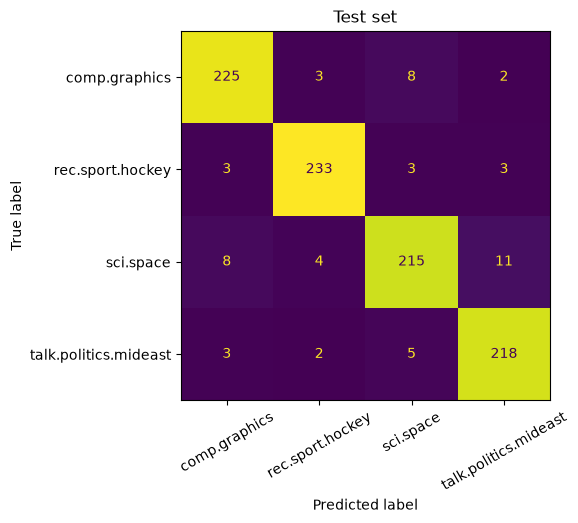

In [25]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=30, colorbar=False)
plt.title("Test set")
plt.show()

""
A macro F1 of 0.942 on 946 posts the model has never seen, very close to the cross-validated 0.940, so the cross-validation estimate was reliable.

The confusion matrix shows where the errors are. Hockey is the easiest topic (233 of 242 right). **Space is the hardest** (recall 0.903): 11 space posts went to Middle East politics and 8 to graphics. Space posts talk about government budgets and politics, and about images and computers, so their vocabulary overlaps with both other forums.
""

""
""
### What the model learned

A Bag-of-Words model is easy to inspect: every column is a word. For each topic, the words that Naive Bayes finds much more likely under that topic than on average are the ones that push a post towards it:
""
""

In [26]:
vectorizer = best_model.named_steps["tfidfvectorizer"]
naive_bayes = best_model.named_steps["multinomialnb"]
feature_names = vectorizer.get_feature_names_out()

log_probs = naive_bayes.feature_log_prob_
for i, topic in enumerate(naive_bayes.classes_):
    top = np.argsort(log_probs[i] - log_probs.mean(axis=0))[-10:][::-1]
    print(f"{topic:<23}", ", ".join(feature_names[top]))

comp.graphics           graphics, 3d, tiff, xv, animation, pov, vga, polygon, computer graphics, siggraph
rec.sport.hockey        hockey, nhl, espn, playoffs, leafs, season, bruins, playoff, rangers, sabres
sci.space               orbit, lunar, hst, spacecraft, shuttle, sky, mars, solar, jupiter, pluto
talk.politics.mideast   armenian, israel, armenians, israeli, turkish, arab, jewish, jews, arabs, muslim


""
These lists are exactly what a person would write for each topic: team names and `nhl` for hockey, `orbit` and `shuttle` for space, file formats (`tiff`) and rendering software (`pov`) for graphics. The bigram `computer graphics` made it into the list too. Being able to read the model like this is one of the big advantages of Bag-of-Words over the models you will meet later this week.

And the mistakes:
""

In [27]:
mistakes = pd.DataFrame({"text": X_test, "true": y_test, "predicted": y_pred})
mistakes = mistakes[mistakes["true"] != mistakes["predicted"]]
for _, row in mistakes.head(4).iterrows():
    print(f"true: {row['true']}   predicted: {row['predicted']}")
    print("   ", " ".join(row["text"].split())[:200], "\n")

true: sci.space   predicted: talk.politics.mideast
    Paul-- for the same reason that many other colonies are founded. Why not? 

true: comp.graphics   predicted: sci.space
    Finding a disk array that can do 180MB/sec. will be difficult. The fastest ones I know about are from Maximum Strategy (IBM also sells these). They can attach HiPPI at up to 144 MB/sec. (64 bit). For  

true: sci.space   predicted: talk.politics.mideast
    How 'bout some more info on that alleged supernova in M-81? I might just break out the scope for this one. ____________________________________________________ "No sir, I don't like it! "-- Mr. Horse  

true: talk.politics.mideast   predicted: sci.space
    Yeah right, sorta like the Indian sub-contient, eh? 



""
The errors are mostly posts that are **short or off-topic**: a one-line reply about colonies (posted in the space forum), a question about disk speed in the graphics forum, a joke about the Indian subcontinent. A person would struggle with several of these too. When most errors look like this, the model has learned what the words can tell it, and a better score would need more context than one post gives.

Finally, the reason we built a pipeline. New text goes straight in:
""

In [28]:
new_posts = [
    "The goalie made 40 saves and the Leafs won in overtime",
    "We rendered the 3D model with a new shading algorithm",
    "The shuttle reached orbit two hours after launch",
]
for post, topic in zip(new_posts, best_model.predict(new_posts)):
    print(f"{topic:<23} {post}")

rec.sport.hockey        The goalie made 40 saves and the Leafs won in overtime
comp.graphics           We rendered the 3D model with a new shading algorithm
sci.space               The shuttle reached orbit two hours after launch


""
""
Because the vectoriser lives inside the pipeline, raw new text goes straight into `predict`. The same lowercasing, the same stop words and the same vocabulary are applied automatically. If you clean text with your own function *before* the pipeline, as the lab does, you must remember to apply that function to every new text too, or its words will not match what the model learned.
""
""

""
""
## 9. Does more preprocessing help?

Sections 2 to 5 described cleaning, stemming and lemmatising. Do they help this classifier? The only way to know is to measure. A vectoriser accepts your own function as `preprocessor` (applied to the raw text) or `tokenizer` (which splits the text into tokens), so the extra steps live inside the pipeline and are cross-validated like everything else.
""
""

In [29]:
def stem_tokens(text):
    tokens = re.findall(r"[a-z]{2,}", text)
    return [snowball.stem(token) for token in tokens if token not in ENGLISH_STOP_WORDS]

best = grid.best_params_
common = {"min_df": best["tfidfvectorizer__min_df"], "ngram_range": best["tfidfvectorizer__ngram_range"]}
nb = lambda: MultinomialNB(alpha=best["multinomialnb__alpha"])

variants = {
    "Tuned model (built-in lowercasing and stop words)": make_pipeline(TfidfVectorizer(stop_words="english", **common), nb()),
    "+ clean_text from section 2": make_pipeline(TfidfVectorizer(preprocessor=clean_text, stop_words="english", **common), nb()),
    "+ clean_text and Snowball stemming": make_pipeline(
        TfidfVectorizer(preprocessor=clean_text, tokenizer=stem_tokens, token_pattern=None, **common), nb()
    ),
    "No stop-word removal": make_pipeline(TfidfVectorizer(**common), nb()),
}
rows = []
for name, model in variants.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({"variant": name, "CV macro F1": scores.mean(), "CV F1 std": scores.std()})
pd.DataFrame(rows).set_index("variant").round(3)

,CV macro F1,CV F1 std
variant,,
Tuned model (built-in lowercasing and stop words),0.940,0.009
+ clean_text from section 2,0.939,0.012
+ clean_text and Snowball stemming,0.938,0.009
No stop-word removal,0.929,0.009


""
None of the extra steps helps:

+ `clean_text` gives the same score (0.939 against 0.940). The vectoriser already lowercases the text, and its default token pattern ignores punctuation, so our regular expressions mostly repeat what it does.
+ Adding Snowball stemming on top does not help either (0.938). With almost 3,000 posts, the model has already seen *launch* and *launches* often enough to learn both.
+ Removing stop words does help: without it the score drops to 0.929.

This is a typical result. **Heavy preprocessing matters most when data is scarce** or the text is very noisy (HTML emails, as in the lab). On a decent amount of clean-ish text, a TF-IDF vectoriser with sensible settings already does most of the work. Lemmatisation was not tested here because tagging every post takes much longer; try it in the lab, where it is one of the steps.
""

""
""
## 10. What Bag-of-Words cannot see

Bag-of-Words and TF-IDF are fast, easy to inspect and surprisingly strong, which is why they are still the first baseline on any text problem. But they have three blind spots, and each one points to what comes next this week.

+ **Word order is lost.** *Dog bites man* and *man bites dog* are the same row. Bigrams help only a little.
+ **Every word is its own column, unrelated to the others.** To the model, `car` and `automobile` are as different as `car` and `banana`.
+ **A word has one meaning.** `bank` gets the same column in *river bank* and *bank account*.

The second blind spot is easy to show. Cosine similarity measures how alike two rows are (1 = same direction, 0 = nothing in common):
""
""

In [30]:
from sklearn.metrics.pairwise import cosine_similarity

sentences = ["I bought a new car", "I purchased a new automobile", "I bought a new banana"]
vectors = TfidfVectorizer(stop_words="english").fit_transform(sentences)
pd.DataFrame(cosine_similarity(vectors).round(2), index=sentences, columns=sentences)

,I bought a new car,I purchased a new automobile,I bought a new banana
I bought a new car,1.00,0.16,0.48
I purchased a new automobile,0.16,1.00,0.16
I bought a new banana,0.48,0.16,1.00


""
*I bought a new car* is **three times more similar to the banana sentence** (0.48) than to *I purchased a new automobile* (0.16), which means the same thing. TF-IDF only sees shared words: the car and banana sentences share `bought` and `new`, while the two that mean the same share only `new` (`I` and `a` are dropped as single characters).

Tomorrow you fix this with **embeddings**: every word, and later every sentence, becomes a dense vector of a few hundred numbers in which words with similar meanings are close together. On Day 3, transformers add the context, so that `bank` gets a different vector in each sentence.
""

""
""
## Summary

| Step | What it does | Tool |
|---|---|---|
| Cleaning | removes what you do not want to count (tags, links, numbers, punctuation) and lowercases | `re.sub` |
| Tokenising | splits text into tokens, usually words | `word_tokenize`, or built into the vectorisers |
| Stop words | removes very common words; careful with negations | `stopwords.words("english")`, `stop_words="english"` |
| Stemming | chops endings with rules; fast, may give non-words | `PorterStemmer`, `SnowballStemmer` |
| Lemmatisation | dictionary form of a word; needs the part of speech | `WordNetLemmatizer`, `nltk.pos_tag` |
| Bag-of-Words | one column per word, values are counts | `CountVectorizer` |
| TF-IDF | counts weighted by how rare the word is, rows scaled to length 1 | `TfidfVectorizer` |
| Vocabulary control | drops rare words, very common words, adds word pairs | `min_df`, `max_df`, `ngram_range` |
| Classifier | the vectoriser and a model in one pipeline, cross-validated and tuned | `make_pipeline`, `MultinomialNB`, `LogisticRegression`, `GridSearchCV` |

The rules that matter most:

+ **Fit the vectoriser on the training data only**, and put it in a pipeline so that cross-validation and new text get the same treatment.
+ **Every preprocessing step is a modelling choice.** Measure it with cross-validation instead of assuming it helps.
+ **Start with TF-IDF and a linear model or Naive Bayes.** It is fast, and it is the baseline that any fancier model must beat.

In the lab you apply the same steps to a harder problem: telling fraudulent emails from normal ones, adding your own features on top of TF-IDF.
""
""

""
""
## Appendix

### A.1 Adding your own features to a sparse matrix

A TF-IDF matrix can be combined with hand-made numeric features, such as the length of the text or a flag for money amounts. `scipy.sparse.hstack` places matrices side by side: the number of rows stays the same and the columns add up. The lab uses this.
""
""

In [31]:
from scipy.sparse import hstack

extra = pd.DataFrame({
    "n_chars": X_train.str.len(),
    "n_digits": X_train.str.count(r"\d"),
})
X_combined = hstack([X_train_vec, extra.to_numpy()]).tocsr()
print("TF-IDF:", X_train_vec.shape, "  extra:", extra.shape, "  combined:", X_combined.shape)

TF-IDF: (2836, 19657)   extra: (2836, 2)   combined: (2836, 19659)


""
""
Two cautions. First, scale matters: `n_chars` can be in the thousands while TF-IDF values are below 1, so for logistic regression you would scale the extra columns (or use a `ColumnTransformer`). Second, `MultinomialNB` needs features that are counts or frequencies, never negative.

### A.2 HashingVectorizer

`CountVectorizer` keeps the whole vocabulary in memory as a dictionary. On millions of documents that can be too much. `HashingVectorizer` skips the vocabulary: it sends each word to one of a fixed number of columns with a hash function. It uses little memory and can process data that does not fit in memory, but you can no longer ask which word a column is, and different words occasionally share a column.
""
""

In [32]:
from sklearn.feature_extraction.text import HashingVectorizer

hashing_model = make_pipeline(HashingVectorizer(n_features=2**18, alternate_sign=False, stop_words="english"), MultinomialNB(alpha=0.01))
scores = cross_val_score(hashing_model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
print(f"HashingVectorizer + Naive Bayes, CV macro F1: {scores.mean():.3f}")

HashingVectorizer + Naive Bayes, CV macro F1: 0.938


0.938, almost the same as the tuned TF-IDF model (0.940), with no vocabulary to store. (`alternate_sign=False` keeps every value positive, which Naive Bayes requires.)

""
""
### A.3 When the text has no signal: headlines and the stock market

Not every text problem can be solved. `data/Combined_News_DJIA.csv` has, for every trading day from 2008 to 2016, the 25 top headlines of the day and whether the Dow Jones index went up (`Label` = 1) or down (0). Can the news predict the market?

Time matters here: we train on 2008 to 2014 and test on 2015 and 2016, so the model never sees the future.
""
""

In [33]:
djia = pd.read_csv("data/Combined_News_DJIA.csv")
headline_columns = [c for c in djia.columns if c.startswith("Top")]
djia["headlines"] = djia[headline_columns].fillna("").astype(str).agg(" ".join, axis=1)
djia["headlines"] = djia["headlines"].str.replace(r"\bb['\"]", " ", regex=True)   # remove the b' prefixes left by the scraper

train_days, test_days = djia[djia["Date"] < "2015-01-01"], djia[djia["Date"] >= "2015-01-01"]
headline_model = make_pipeline(TfidfVectorizer(stop_words="english", min_df=2, ngram_range=(1, 2)), LogisticRegression(max_iter=1000))
headline_model.fit(train_days["headlines"], train_days["Label"])

accuracy = (headline_model.predict(test_days["headlines"]) == test_days["Label"]).mean()
majority = max(test_days["Label"].mean(), 1 - test_days["Label"].mean())
print(f"Training days: {len(train_days)}   Test days: {len(test_days)}")
print(f"Model accuracy: {accuracy:.3f}   Always predicting the most frequent label: {majority:.3f}")

Training days: 1611   Test days: 378
Model accuracy: 0.495   Always predicting the most frequent label: 0.508


""
""
The model does slightly *worse* than always guessing the most frequent label. That is the honest answer: world headlines do not predict whether the index goes up the next day, and a pipeline that scores 0.94 on forum topics finds nothing here. Always compare with a baseline before believing a text model, and be suspicious of a high score on this kind of problem: it usually means the test set leaked into training, for example through a random split that mixes future days into the training set.
""
""